# 02_FeatureEngineering Notebook

This notebook is used to create the data set which can be used for Training.

The image files are processed to create features if not the full image is used for training. At the end all the data is save as gold layer data

## 1. Import libaries and define parameters

In [1]:
import os
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

from PIL import Image, ExifTags

In [2]:
# path to pictures and meta data for mpictures
silverDir = r'C:\Users\domin\OneDrive\Dokumente\Privat\AlgaeBiotech\IGB-Sensorfusion\Data\02_silver'
goldDir = r'C:\Users\domin\OneDrive\Dokumente\Privat\AlgaeBiotech\IGB-Sensorfusion\Data\03_gold'
metaDataPath = r'C:\Users\domin\OneDrive\Dokumente\Privat\AlgaeBiotech\IGB-Sensorfusion\Data'
metaDataFile  = r'\imageMetaData.xlsx'

## 2. Create dataframe for data set

In [3]:
# read meta data to dataframe
df = pd.read_excel(metaDataPath + metaDataFile)

In [4]:
# extend df with image filename
fileList = [f'IMG_{name}.JPG' for name in df['imgNumber']]
df['imgFileName'] = fileList
df.head()

,concentration,probeQuantity,iso,imgNumber,imgFileName
0,0.5,20,800,1542,IMG_1542.JPG
1,0.5,20,800,1543,IMG_1543.JPG
2,0.5,20,800,1544,IMG_1544.JPG
3,0.5,20,800,1545,IMG_1545.JPG
4,0.5,40,800,1546,IMG_1546.JPG


## 3. Analysis of image silver data

### Mean RGB values

In [5]:
# calculate mean RGB values for each image and channel, with and without the max pixels
red = []
redEx = []
green = []
greenEx = []
blue = []
blueEx = []
for filename in df['imgFileName']:
    filepath = os.path.join(silverDir, filename)
    img = Image.open(filepath).convert("RGB")
    # Convert to NumPy array
    img_array = np.array(img)  # Shape: (height, width, 3)
    # Extract R, G, B channels
    R = img_array[:, :, 0]
    G = img_array[:, :, 1]
    B = img_array[:, :, 2]
    # calculate the mean values
    red.append(R.mean())
    green.append(G.mean())
    blue.append(B.mean())
    # calculate the mean values without pixels where all channels have max values
    redEx.append(R[((R != 255) & (G != 255) & (B != 255))].mean())
    greenEx.append(G[((R != 255) & (G != 255) & (B != 255))].mean())
    blueEx.append(B[((R != 255) & (G != 255) & (B != 255))].mean())    

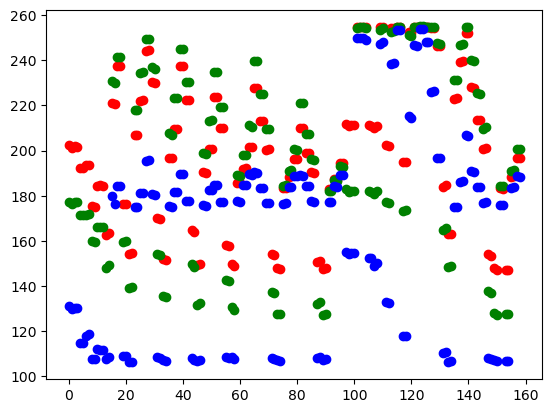

In [6]:
plt.scatter(range(len(red)), red, c='r')
plt.scatter(range(len(red)), green, c='g')
plt.scatter(range(len(red)), blue, c='blue')
plt.show()

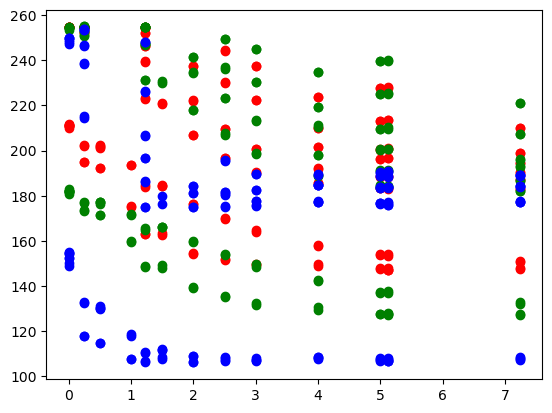

In [7]:
plt.scatter(df['concentration'], red, c='r')
plt.scatter(df['concentration'], green, c='g')
plt.scatter(df['concentration'], blue, c='blue')
plt.show()

### Min and max RGB values

In [8]:
print(img.size)
print(img.size[0]*img.size[1])

(340, 340)
115600


In [9]:
# check number of pixels that are either 0 or 255, separately for each channel
totalPixels = 340*340
redMinMax = sum(sum((R == 0) | (R == 255)))
greenMinMax = sum(sum((G == 0) | (G == 255)))
blueMinMax = sum(sum((B == 0) | (B == 255)))

print('Red:', redMinMax, redMinMax/totalPixels) 
print('Green:', greenMinMax, greenMinMax/totalPixels) 
print('Blue:', blueMinMax, blueMinMax/totalPixels) 

Red: 78519 0.6792301038062284
Green: 77829 0.6732612456747404
Blue: 77958 0.6743771626297578


In [10]:
# check where all channels have extreme values
print(sum(sum(((R == 255) & (G == 255) & (B == 255)))) /totalPixels)
print(sum(sum(((R == 0) & (G == 0) & (B == 0)))) /totalPixels)

0.6565657439446366
0.0


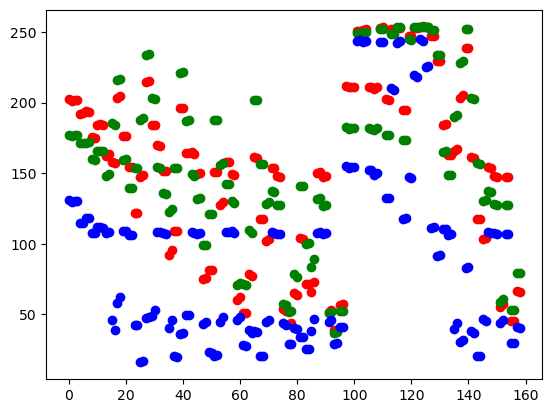

In [11]:
plt.scatter(range(len(red)), redEx, c='r')
plt.scatter(range(len(red)), greenEx, c='g')
plt.scatter(range(len(red)), blueEx, c='blue')
plt.show()

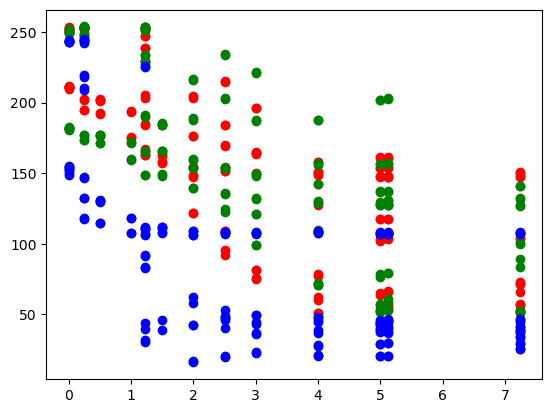

In [12]:
plt.scatter(df['concentration'], redEx, c='r')
plt.scatter(df['concentration'], greenEx, c='g')
plt.scatter(df['concentration'], blueEx, c='blue')
plt.show()

In [13]:
maskArray = np.ma.masked_array(data = R, mask = ((R == 255) & (G == 255) & (B == 255)))

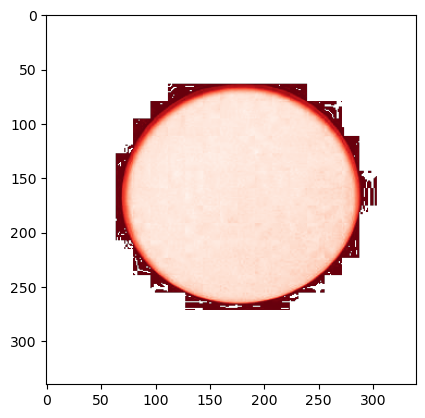

In [14]:
plt.imshow(maskArray, cmap='Reds')

## 5. Create dataframe for combined data

In [15]:
# extend df with meta and label data with mean RGB values if images
df['red'] = red
df['green'] = green
df['blue'] = blue
df['redEx'] = redEx
df['greenEx'] = greenEx
df['blueEx'] = blueEx
df

,concentration,probeQuantity,iso,imgNumber,imgFileName,red,green,blue,redEx,greenEx,blueEx
0,0.50,20,800,1542,IMG_1542.JPG,202.267379,177.403036,130.979161,202.267379,177.403036,130.979161
1,0.50,20,800,1543,IMG_1543.JPG,201.236557,176.150268,129.861151,201.236557,176.150268,129.861151
2,0.50,20,800,1544,IMG_1544.JPG,201.829144,177.143131,130.098434,201.829144,177.143131,130.098434
3,0.50,20,800,1545,IMG_1545.JPG,201.773849,177.068339,130.089377,201.773849,177.068339,130.089377
4,0.50,40,800,1546,IMG_1546.JPG,192.273503,171.378659,114.703927,192.273503,171.378659,114.703927
...,...,...,...,...,...,...,...,...,...,...,...
154,5.13,40,800,1696,IMG_1696.JPG,147.258149,127.413166,106.833875,147.258149,127.413166,106.833875
155,5.13,40,6400,1697,IMG_1697.JPG,188.505735,191.007561,183.636877,44.934881,52.928374,29.910987
156,5.13,40,6400,1698,IMG_1698.JPG,188.833313,191.313711,183.863676,45.375123,53.307572,29.989089
157,5.13,40,12800,1699,IMG_1699.JPG,196.860095,200.814481,188.932292,66.198876,79.114278,40.834907


Training Images are: 1542 - 1652 / 0 - 110

Testing Images are: 1653 - 1700 / 111 - 158

Images with label zero: 1639 - 1652 / 97 - 110

In [20]:
# save data together in one file
df.to_excel(goldDir + r'\combinedData.xlsx', index=False)
# split data for training and testing
df.iloc[:111, :].to_excel(goldDir + r'\combinedTrainData.xlsx', index=False)
df.iloc[111:, :].to_excel(goldDir + r'\combinedTestData.xlsx', index=False)